# Chapter 3: Polynomial Regression excercise

In [1]:
%reset
low_memory=False

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

Once deleted, variables cannot be recovered. Proceed (y/[n])?  y


## 3.1 Introduction & Motivation

While linear regression in itself is an interesting tool, it can only bring us so far. At a certain point data will no longer have a linear connection and we will have to resort to using **polynomial regression**. Using an example regarding cars we will compare both forms of regression and try to end up with the best model possible.

## 3.2 Problem setting

Every car has a certain distance it can drive per unit of fuel. In the industry, this is measured in **MPG** (or Miles Per Gallon). The higher the MPG, the more fuel-efficient a certain car is. Generally speaking we want a high MPG to save money on fuel cost.

## 3.3 Model

Go to canvas and donload the file "Auto.csv" from module 3. This data contains the required dataset.

In [89]:
df = pd.read_csv("Auto.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


##### Question 1: Have a look at the data. Can you spot a column we will not be able to use? Why is this? Can you think of a way to transform this type of data so we could use it after all? Would work for the data we currently have? Elaborate.

We will not be able to use the column called "car name". This is because car name is a string of text instead of a number. Regression only works with numbers and not with labels, thus we are currently unable to use this parameter.

We could theoretically convert each string into integers as dummy variables. These values could then be used by the model. However, dummy variables only work in a binary format. Since each car name is unique there are too many names to convert and a simple 0 - 1 system won't work.

##### Question 2: Drop the extra column. Create a train_test split from the remaining data. Make sure **not** to include the final mpg colum in your "X" dataset!

In [91]:
df = df.drop(['car name'], axis=1)

Since we are working with a lot of variables, it is time to plot a heatmap.

<Axes: >

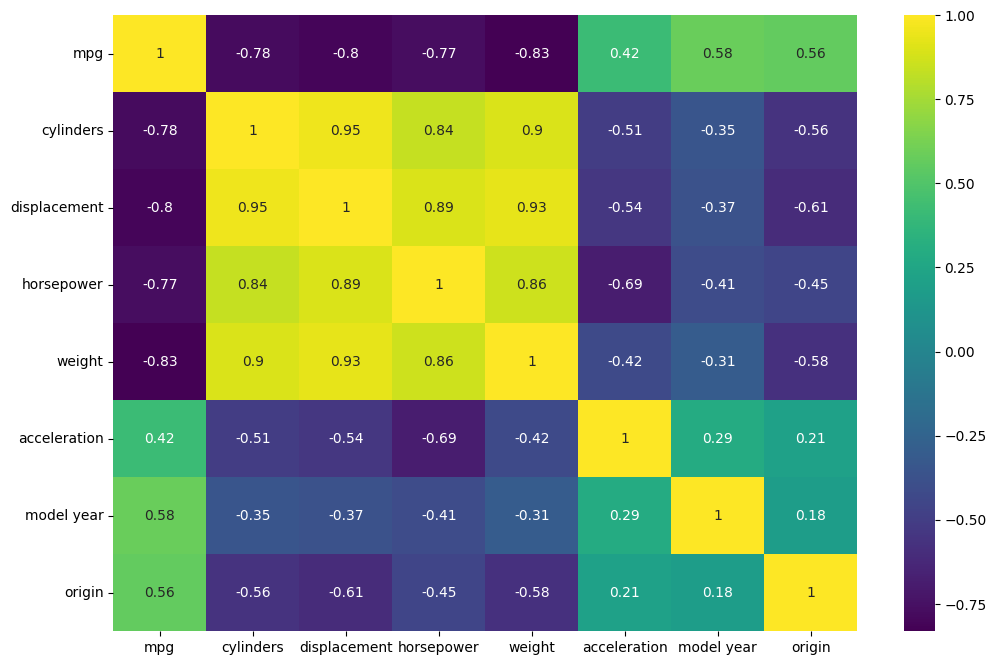

In [92]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),cmap='viridis',annot=True)

##### Question 3: Explore the heatmap. Which variables would you expect to be useful when trying to predict MPG?

The higher the number of each cell, the more the variables in that row and column have a positive linear connection. The lower the number of each cell, the more the variables in that row and column have a negative linear connection. Both are good indicators the variables depend on each other.

The closer a number is to zero, the less likely the variables in that row and column have a negative connection.

In this case, we can expect variables like 'weight' and 'displacement' to have a connection with 'mpg', while 'acceleration' likely won't.

##### Question 4: Plot the data using "weight" as the independant variable and 'MPG' as the dependant variable. Fit a model using linear regression. Calculate $R^2$ and the MSE. Is this any good? Show the model on a plot and elaborate.

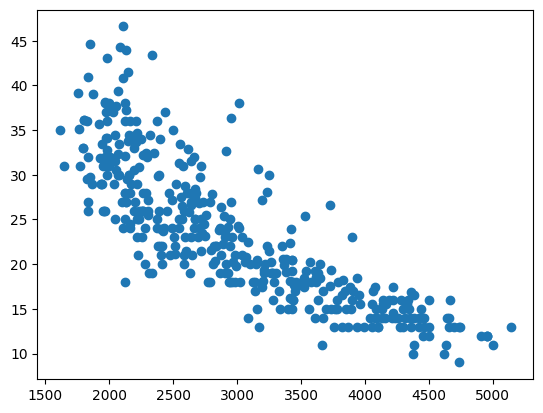

In [93]:
plt.plot(df["weight"], df["mpg"], 'o')
plt.show()

The R2 score of the model on the train set is: 0.6780128988922917
The MSE of the model on the test set is: 15.821924228587429


Text(0, 0.5, 'Y')

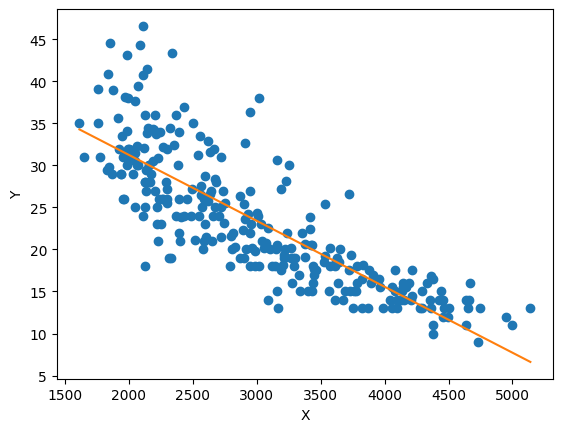

In [94]:
X_train, X_test, y_train, y_test = train_test_split(df["weight"], df["mpg"], test_size=0.3, random_state=42)
model = LinearRegression()
model.fit(X_train.to_numpy().reshape(-1,1), y_train)
print('The R2 score of the model on the train set is:', model.score(X_train.to_numpy().reshape(-1,1), y_train))
print('The MSE of the model on the test set is:', mean_squared_error(model.predict(X_test.to_numpy().reshape(-1,1)), y_test))
plt.plot(X_train, y_train, 'o')
plt.plot([X_train.min(), X_train.max()], [model.predict([[X_train.min()]]), model.predict([[X_train.max()]])])
plt.xlabel("X")
plt.ylabel("Y")

$R^2$ of our model is 0.68, meaning 68% of our data is explained by the model. While this isn't exactly bad, it's also not great. There is certainly room for improvement here.

An explanation for this score is that while our model follows a straight path, our data has a slight curve. Our model does not follow these curves and is **underfitting**.

As for the MSE, the number we currently have does not tell us anything about the model. We will have to make some changes and compare the MSE.
##### Question 5: Create a model using polynomial regression. Make an educated guess on the degree of the function and plot the model. Calculate the $R^2$ and MSE. Compare this to the metrics of your linear regression model. Is there an improvement?

The R2 score of the model on the train set is: 0.6971823051844364
The MSE of the model on the test set is: 14.045818694396623


Text(0, 0.5, 'Y')

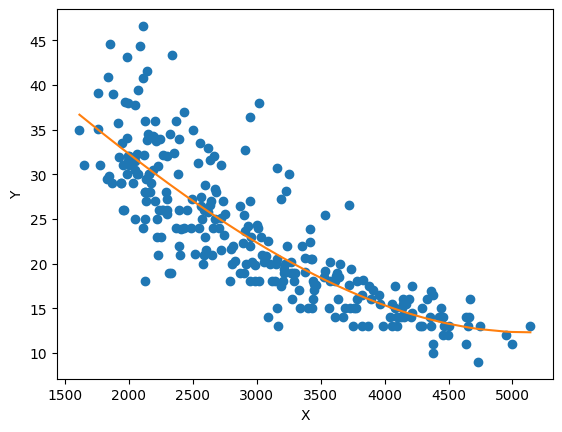

In [95]:
X_train, X_test, y_train, y_test = train_test_split(df["weight"], df["mpg"], test_size=0.3, random_state=42)
model = LinearRegression()
pol_exp = PolynomialFeatures(degree=3)
model.fit(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1)), y_train)
print('The R2 score of the model on the train set is:', model.score(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1)), y_train))
print('The MSE of the model on the test set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_test.to_numpy().reshape(-1,1))), y_test))
plt.plot(X_train, y_train, 'o')
plt.plot(X_train.sort_values().to_numpy(), model.predict(pol_exp.fit_transform(X_train.sort_values().to_numpy().reshape(-1,1))))
plt.xlabel("X")
plt.ylabel("Y")

We can see our model now follows the data more closely. Our score for $R^2$ has improved slightly too. Our MSE of 14.0 is lower than the MSE of the linear model (15.8). We can speak of a certain improvement in our model, however there is still room for further improvement.

## 3.4 Model evaluation

We already did some early model evaluating, but we can look for a better degree of our function to improve the model.

##### Question 6: Figure out what the best degree of the function is. Calculate the MSE for each degree on training and testing data and plot the values to figure out the best value. be careful of overfitting!

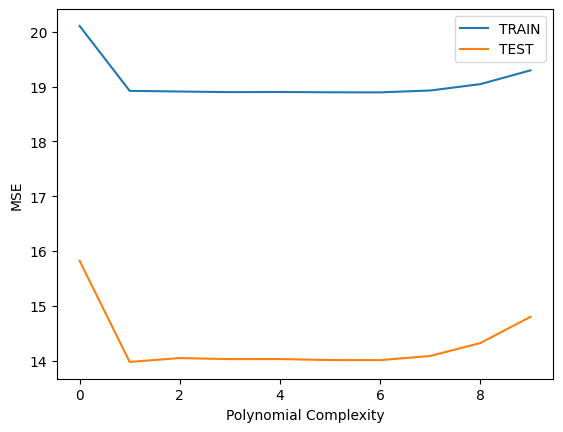

In [100]:
train_mse_errors = []
test_mse_errors = []

X_train, X_test, y_train, y_test = train_test_split(df["weight"], df["mpg"], test_size=0.3, random_state=42)

for d in range(1,11):
    model = LinearRegression()
    pol_exp = PolynomialFeatures(degree=d)
    model.fit(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1)), y_train)
    
    train_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1))), y_train)
    test_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_test.to_numpy().reshape(-1,1))), y_test)
    
    train_mse_errors.append(train_MSE)
    test_mse_errors.append(test_MSE)

plt.plot(train_mse_errors,label='TRAIN')
plt.plot(test_mse_errors,label='TEST')
plt.xlabel("Polynomial Complexity")
plt.ylabel("MSE")
plt.legend()

The lowest MSE is at position 1, meaning our model will perform best with a degree of 2.

In [150]:
X_train, X_test, y_train, y_test = train_test_split(df["weight"], df["mpg"], test_size=0.3, random_state=42)
model = LinearRegression()
pol_exp = PolynomialFeatures(degree=4)
model.fit(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1)), y_train)
print('The R2 score of the model on the train set is:', model.score(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1)), y_train))
print('The MSE of the model on the test set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_test.to_numpy().reshape(-1,1))), y_test))

The R2 score of the model on the train set is: 0.6973564005836862
The MSE of the model on the test set is: 14.026595704765752


## 3.5 Excercises

##### Question 1: See section 3.3

##### Question 2: See section 3.3

##### Question 3: See section 3.3

##### Question 4: See section 3.3

##### Question 5: See section 3.3

##### Question 6: See section 3.5

##### Question 7: A new car just came on the market with a weight of 2071 pounds. What MPG can we expect of this car?

In [147]:
X_train, X_test, y_train, y_test = train_test_split(df["weight"], df["mpg"], test_size=0.3, random_state=42)

model = LinearRegression()
pol_exp = PolynomialFeatures(degree=2)
model.fit(pol_exp.fit_transform(X_train.to_numpy().reshape(-1,1)), y_train)
model.predict(pol_exp.fit_transform([[2071]]))

array([31.51751698])

According to our current model a car with a weight of 2071 pounds would result in a MPG of 31.52.

##### Question 8: Have another look at the heatmap from section 3.3. Can you spot another variable that might bring an improvement to the model? Figure out the best degree and retrain the model with 'weight' and the added variabele. Calculate $R^2$ and the MSE. Did the model improve?

Another variable that seems likely to have a predictive impact would be displacement. Let's plot this data.

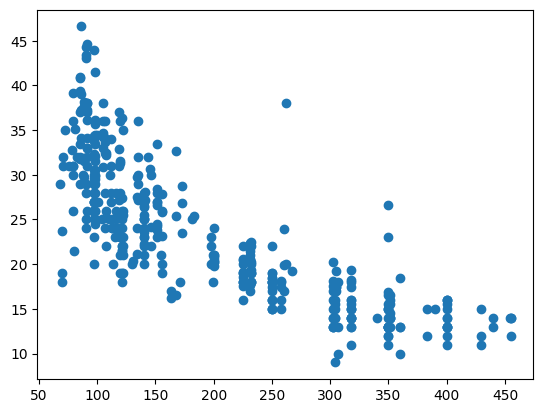

In [111]:
plt.plot(df["displacement"], df["mpg"], 'o')
plt.show()

We can see a curve in this data, meaning polynomial regression will likely result in a good model. To check this, we need to add the parameter to the model, figure out the best degree of the function and retrain the model.

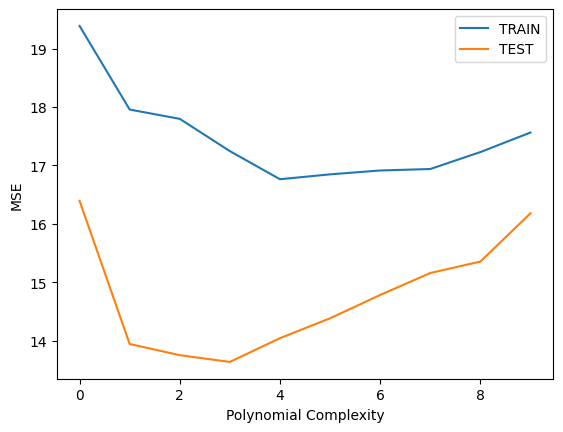

In [114]:
train_mse_errors = []
test_mse_errors = []

X_train, X_test, y_train, y_test = train_test_split(df[["weight","displacement"]], df["mpg"], test_size=0.3, random_state=42)

for d in range(1,11):
    model = LinearRegression()
    pol_exp = PolynomialFeatures(degree=d)
    model.fit(pol_exp.fit_transform(X_train), y_train)
    
    train_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_train)), y_train)
    test_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_test)), y_test)
    
    train_mse_errors.append(train_MSE)
    test_mse_errors.append(test_MSE)

plt.plot(train_mse_errors,label='TRAIN')
plt.plot(test_mse_errors,label='TEST')
plt.xlabel("Polynomial Complexity")
plt.ylabel("MSE")
plt.legend()

Interesting! Here we see the lowest MSE is at position 3, or a degree of 4. To see what effect this has on the model, we will retrain it using a degree of 4 and calculate $R^2$ and the MSE.

In [151]:
X_train, X_test, y_train, y_test = train_test_split(df[["weight","displacement"]], df["mpg"], test_size=0.3, random_state=42)
model = LinearRegression()
pol_exp = PolynomialFeatures(degree=4)
model.fit(pol_exp.fit_transform(X_train), y_train)
print('The R2 score of the model on the train set is:', model.score(pol_exp.fit_transform(X_train), y_train))
print('The MSE of the model on the test set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_test)), y_test))

The R2 score of the model on the train set is: 0.7238548788186449
The MSE of the model on the test set is: 13.638052925768186


$R^2$ is 0.72 which is already an improvement and the MSE is 13.6 which is an improvement over 14.0! We can conclude that the aditional parameter did bring an improvement to out model!

##### Question 9: Figure out which columns give the best result. Retrain your models as many times as needed using different columns. figure out the best degree and calculate $R^2$ and the MSE. What is the best model you can achieve?

Our first thought would be to train a model using all available data. We will figure out the best degree, then retrain and evaluate the model.

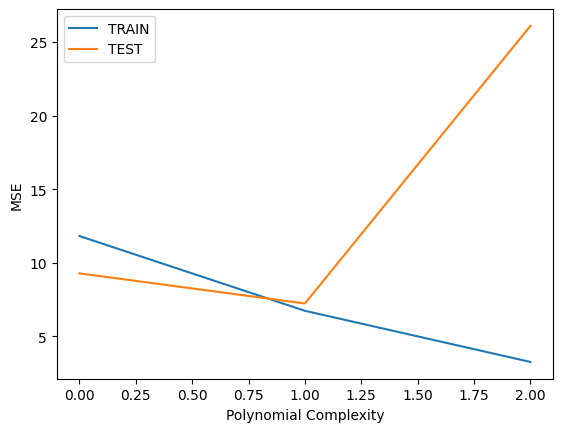

In [124]:
train_mse_errors = []
test_mse_errors = []

X_train, X_test, y_train, y_test = train_test_split(df.drop(['mpg'], axis=1), df["mpg"], test_size=0.3, random_state=42)

for d in range(1,4):
    model = LinearRegression()
    pol_exp = PolynomialFeatures(degree=d)
    model.fit(pol_exp.fit_transform(X_train), y_train)
    
    train_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_train)), y_train)
    test_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_test)), y_test)
    
    train_mse_errors.append(train_MSE)
    test_mse_errors.append(test_MSE)

plt.plot(train_mse_errors,label='TRAIN')
plt.plot(test_mse_errors,label='TEST')
plt.xlabel("Polynomial Complexity")
plt.ylabel("MSE")
plt.legend()

In [129]:
X_train, X_test, y_train, y_test = train_test_split(df.drop(['mpg'], axis=1), df["mpg"], test_size=0.3, random_state=42)
model = LinearRegression()
pol_exp = PolynomialFeatures(degree=2)
model.fit(pol_exp.fit_transform(X_train), y_train)
print('The R2 score of this model on the train set is:', model.score(pol_exp.fit_transform(X_train), y_train))
print('The MSE score of this model on the train set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_train)), y_train))
print('The MSE score of this model on the test set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_test)), y_test))

The R2 score of this model on the train set is: 0.8922105030972135
The MSE score of this model on the train set is: 6.731559578157166
The MSE score of this model on the test set is: 7.2288941951344325


We now get an MSE of 7.2. That's great! However, maybe the model is a bit too complex. Let's try reducing the amount of features to see if we can get an even better model.

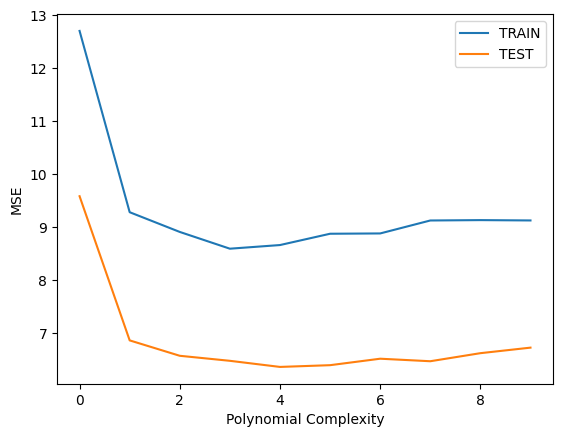

In [118]:
train_mse_errors = []
test_mse_errors = []

X_train, X_test, y_train, y_test = train_test_split(df[["weight","model year"]], df["mpg"], test_size=0.3, random_state=42)

for d in range(1,11):
    model = LinearRegression()
    pol_exp = PolynomialFeatures(degree=d)
    model.fit(pol_exp.fit_transform(X_train), y_train)
    
    train_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_train)), y_train)
    test_MSE = mean_squared_error(model.predict(pol_exp.fit_transform(X_test)), y_test)
    
    train_mse_errors.append(train_MSE)
    test_mse_errors.append(test_MSE)

plt.plot(train_mse_errors,label='TRAIN')
plt.plot(test_mse_errors,label='TEST')
plt.xlabel("Polynomial Complexity")
plt.ylabel("MSE")
plt.legend()

In [130]:
X_train, X_test, y_train, y_test = train_test_split(df[["weight","model year"]], df["mpg"], test_size=0.3, random_state=42)
model = LinearRegression()
pol_exp = PolynomialFeatures(degree=5)
model.fit(pol_exp.fit_transform(X_train), y_train)
print('The R2 score of this model on the train set is:', model.score(pol_exp.fit_transform(X_train), y_train))
print('The MSE score of this model on the train set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_train)), y_train))
print('The MSE score of this model on the test set is:', mean_squared_error(model.predict(pol_exp.fit_transform(X_test)), y_test))

The R2 score of this model on the train set is: 0.8613479330193123
The MSE score of this model on the train set is: 8.658957285577687
The MSE score of this model on the test set is: 6.357475349410288


After some trial and error we end up with a model that only takes weight and model year as parameters. Here we achieve an MSE of 6.35, which is once more a small improvement!

Is the for certain the best model we can make? No way to truly know! There are always more parameter combinations you can explore, and other settings you can tweak. However by analysing the data, picking the right model, calculating the correct degree and exploring the best input parameters we can create a great model. We will never end up with a model where $R^2$ is 1 and the MSE is 0, so we need to create one ourselves that we are happy with.